<!-- m6:deber -->
# Módulo 6 · Deber — Detector bayesiano de fraude para PagoYa
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · individual · ≈ 3 horas

**Entrega:** Colab → **Archivo → Guardar (Ctrl+S)** → en *Repositorio* elija **el suyo** → ruta **`deber/deber.ipynb`** → mensaje `Deber`.
**Plazo: domingo 15-nov-2026, 11:00.** Un solo archivo: este cuaderno, ejecutado, con sus respuestas y el informe al final.

**Datos personalizados:** la API simulada genera transacciones **distintas para cada estudiante** a partir de su nombre. Sus cifras no coincidirán con las de sus compañeros; el docente puede regenerar sus datos para verificar.

| Parte | Tema | Puntos |
|---|---|---|
| 1 | Regresión logística bayesiana en PyMC (priors, muestreo y diagnóstico) | 20 |
| 2 | Comparación con boosting (XGBoost): discriminación y calibración | 20 |
| 3 | Modelo jerárquico por provincia | 20 |
| 4 | Decisión con matriz de costos e incertidumbre | 20 |
| 5 | Informe ejecutivo para el comité de riesgos | 20 |
| | **Total** | **100** |

**En cada parte:** código correcto y ejecutado (8) · resultados y diagnósticos (6) · interpretación propia (6).
Aquí no hay `___` para completar: el enunciado guía, **el código lo escribe usted** (puede reutilizar el de las clases 2 y 3).

## 0. Preparación

In [1]:
import importlib, subprocess, sys
for paquete in ['pymc']:
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete])
import os, urllib.request, warnings, logging
URL = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/main/curso.py'
if not os.path.exists('curso.py'):
    urllib.request.urlretrieve(URL, 'curso.py')
import curso
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pymc as pm
logging.getLogger('pymc').setLevel(logging.ERROR)
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, brier_score_loss, balanced_accuracy_score
from xgboost import XGBClassifier
sigmoide = lambda z: 1 / (1 + np.exp(-z))
print('Listo · curso', curso.VERSION)

Listo · curso m6-2026.11


**Escriba su nombre exactamente como en las clases ('Apellido Nombre').** Sus datos dependen de él.

In [2]:
NOMBRE = 'Vizuete Esteban'                                               # ✏️ 'Apellido Nombre'
df = curso.datos_deber(NOMBRE)                               # datos personalizados + columna 'ratio'
df.head()

Huella de datos: Vizuete Esteban · semilla 392258
Descargados 3006 eventos en 7 páginas de /v1/transacciones
Datos limpios: 2996 transacciones · tasa de fraude 9.71%


,evento_id,timestamp,id,edad,provincia,antiguedad_meses,ingreso_mensual,tipo,canal,categoria,monto,dispositivo_nuevo,distancia_km,intentos_pin,fraude,hora,ratio
0,TX-000000,2026-10-23 14:16:34-05:00,U0550,34.0,El Oro,13,1063.25,transferencia,app,persona,132.77,0,0.1,1,0,14,0.124872
1,TX-000001,2026-09-15 18:21:32-05:00,U0606,24.0,Guayas,19,517.31,transferencia,app,persona,55.93,0,4.9,1,0,18,0.108117
2,TX-000002,2026-09-12 10:15:03-05:00,U0128,18.0,Azuay,8,406.61,transferencia,app,persona,50.13,0,1.1,1,0,10,0.123288
3,TX-000003,2026-10-16 11:26:35-05:00,U0501,32.0,Pichincha,54,1592.64,transferencia,app,persona,91.89,0,0.4,1,0,11,0.057697
4,TX-000004,2026-09-11 03:23:22-05:00,U0714,25.0,Guayas,58,467.32,pago_comercio,app,supermercado,60.99,0,0.4,1,0,3,0.130510


In [3]:
# Partición FIJA (no la cambie): 70 % entrenamiento, 30 % prueba, estratificada
cols = ['dispositivo_nuevo', 'distancia_km', 'ratio', 'intentos_pin', 'hora']
X_train, X_test, y_train, y_test = train_test_split(df[cols], df['fraude'], test_size=0.3,
                                                    stratify=df['fraude'], random_state=42)
print('Entrenamiento:', X_train.shape, '· Prueba:', X_test.shape, '· tasa de fraude:', round(df['fraude'].mean(), 4))

Entrenamiento: (2097, 5) · Prueba: (899, 5) · tasa de fraude: 0.0971


---
## Parte 1 · Regresión logística bayesiana en PyMC (20 pts)
1. **Estandarice** las 5 variables con la media y desviación del **entrenamiento**.
2. Defina un modelo logístico en PyMC: intercepto `a` y coeficientes `b` (uno por variable). **Elija y justifique las priors** (en la celda de texto).
3. Muestree con **4 cadenas**, `tune=1000`, 1000 muestras y `random_seed=42`.
4. Muestre la tabla `curso.diagnostico(...)` y verifique **R-hat ≤ 1,01** y **ESS > 400** en todos los parámetros.
5. Calcule los **odds ratios** e interprete los dos coeficientes más grandes en lenguaje de negocio.
6. Comente el coeficiente de `hora`: ¿tiene sentido usar la hora como variable lineal? (pista: madrugada).

In [4]:
# ✏️ Escriba aquí su modelo (estandarización, priors, muestreo con 4 cadenas y tabla de diagnóstico)
# 1) Estandarización con media y desviación del ENTRENAMIENTO
media = X_train.mean()
desv  = X_train.std()
Z_train = ((X_train - media) / desv).values
Z_test  = ((X_test  - media) / desv).values

# 2) Modelo logístico bayesiano
with pm.Model() as modelo_log:
    a = pm.Normal('a', mu=0, sigma=2)                       # intercepto: prior débilmente informativa
    b = pm.Normal('b', mu=0, sigma=1, shape=len(cols))      # coeficientes: regularizan (efectos moderados)
    pm.Bernoulli('obs', logit_p=a + pm.math.dot(Z_train, b), observed=y_train.values)
    # 3) 4 cadenas, tune=1000, 1000 muestras, semilla fija
    tr_log = pm.sample(1000, tune=1000, chains=4, random_seed=42, progressbar=False)

# 4) Tabla de diagnóstico + odds ratios
diag = curso.diagnostico(tr_log, ['a', 'b'])
diag.index = ['intercepto'] + cols
diag['odds_ratio'] = np.exp(diag['media']).round(3)
diag

,media,desv,ic_3%,ic_97%,r_hat,ess,odds_ratio
intercepto,-3.2291,0.1334,-3.4835,-2.9906,1.0011,2822.4634,0.040
dispositivo_nuevo,0.9831,0.0694,0.8556,1.1174,1.0010,3284.1199,2.673
distancia_km,0.5097,0.0757,0.3701,0.6539,1.0001,4000.0000,1.665
ratio,0.9337,0.0812,0.7825,1.0933,1.0000,3782.1738,2.544
intentos_pin,0.5740,0.0735,0.4351,0.7093,1.0002,3494.6872,1.775
hora,-0.4214,0.0899,-0.5961,-0.2489,1.0001,4000.0000,0.656


**✍️ Respuesta:**

**Justificación de priors:**

Intercepto: Normal(0, 2). En la escala log‑odds, esto abarca tasas base entre ≈ 1 % y ≈ 99 %, sin imponer una tasa específica. Es coherente con una tasa de fraude esperada entre 5 % y 15 %.

Coeficientes: Normal(0, 1). Funciona como regularización (ridge bayesiano): penaliza efectos enormes por desviación estándar de cada predictor, evita sobreajuste con una variable tan predictiva como dispositivo_nuevo y se corresponde con la escala estandarizada (un OR entre ~0,37 y ~2,7 por +1 σ). Es una prior débilmente informativa, estándar para regresión logística bayesiana.

**Interpretación:**

dispositivo_nuevo (OR = 2,67): si un cliente opera desde un dispositivo que nunca había usado, el odds de fraude se multiplica casi por 3, aun controlando distancia, monto, PIN y hora. Es la señal más potente: en producción, un dispositivo nuevo debería disparar verificación adicional (OTP, selfie, llamada).

ratio monto/ingreso (OR = 2,54): un incremento de 1 desviación estándar en el cociente monto/ingreso multiplica ×2,5 el odds de fraude. Traducido: una transacción que compromete una fracción inusualmente alta del ingreso del usuario es fuertemente sospechosa, incluso sin otros indicadores.

Sobre hora (OR = 0,66, signo negativo): el coeficiente sugiere que, conforme avanza el día, el riesgo baja. Esto es consistente con la intuición de que el fraude se concentra en la madrugada (0–5 h). Sin embargo, usar la hora como variable lineal es conceptualmente incorrecto: el modelo impone un efecto monótono (cada hora cuenta igual), cuando en realidad el patrón es cíclico y no lineal (pico en madrugada, valle al mediodía, ligero repunte en la noche). Además, la hora 23 y la hora 0 son vecinas en la vida real pero el modelo las trata como extremos opuestos (23 muy lejos de 0).





---
## Parte 2 · Comparación con boosting (20 pts)
1. Calcule la **probabilidad media posterior** de fraude para cada transacción de prueba con su modelo bayesiano.
2. Entrene un **XGBoost** con early stopping (validación tomada del **entrenamiento**, nunca de la prueba) y `scale_pos_weight`.
3. Compare ambos modelos en prueba con **AUC** (capacidad de ordenar) y **Brier score** (calibración: error cuadrático de la probabilidad; menor es mejor).
4. Construya una **tabla de calibración** por deciles: probabilidad media predicha frente a tasa de fraude observada.
5. Interprete: ¿cuál ordena mejor?, ¿cuál da probabilidades más confiables?, ¿por qué `scale_pos_weight` afecta la calibración?

In [5]:
# ✏️ Probabilidades del modelo bayesiano, XGBoost con early stopping, AUC, Brier y tabla de calibración
# 1) Probabilidad media posterior por muestra de la posterior
a_s = tr_log.posterior['a'].values.reshape(-1)               # (n_draws,)
b_s = tr_log.posterior['b'].values.reshape(-1, len(cols))    # (n_draws, 5)
logit_test = a_s[:, None] + b_s @ Z_test.T                   # (n_draws, n_test)
p_samples  = sigmoide(logit_test)                            # distribución posterior por transacción
p_bayes    = p_samples.mean(0)                               # media posterior por transacción

# 2) XGBoost con early stopping (validación SOLO del entrenamiento) y scale_pos_weight
from sklearn.model_selection import train_test_split as _tts
X_tr2, X_val, y_tr2, y_val = _tts(X_train, y_train, test_size=0.2,
                                  stratify=y_train, random_state=42)
spw = (y_tr2 == 0).sum() / (y_tr2 == 1).sum()
xgb = XGBClassifier(
    n_estimators=1000, learning_rate=0.05, max_depth=4,
    subsample=0.9, colsample_bytree=0.9,
    scale_pos_weight=spw,
    eval_metric='logloss', early_stopping_rounds=50,
    random_state=42, n_jobs=-1
)
xgb.fit(X_tr2, y_tr2, eval_set=[(X_val, y_val)], verbose=False)
p_xgb = xgb.predict_proba(X_test)[:, 1]

# 3) AUC y Brier
from sklearn.metrics import roc_auc_score, brier_score_loss
print(f'AUC  · bayes {roc_auc_score(y_test, p_bayes):.4f} · xgb {roc_auc_score(y_test, p_xgb):.4f}')
print(f'Brier· bayes {brier_score_loss(y_test, p_bayes):.4f} · xgb {brier_score_loss(y_test, p_xgb):.4f}')

# 4) Tabla de calibración por deciles
def tabla_calib(y, p, modelo):
    d = pd.DataFrame({'y': np.asarray(y), 'p': np.asarray(p)})
    d['dec'] = pd.qcut(d['p'], 10, labels=False, duplicates='drop')
    t = d.groupby('dec').agg(n=('y','size'), p_media=('p','mean'), tasa_obs=('y','mean'))
    t['modelo'] = modelo
    return t
tabla_cal = pd.concat([tabla_calib(y_test, p_bayes, 'bayes'),
                       tabla_calib(y_test, p_xgb,   'xgb')])
tabla_cal

AUC  · bayes 0.8549 · xgb 0.9077
Brier· bayes 0.0673 · xgb 0.0631


,n,p_media,tasa_obs,modelo
dec,,,,
0,90,0.005370,0.011111,bayes
1,90,0.008772,0.033333,bayes
2,90,0.012326,0.011111,bayes
3,90,0.016203,0.011111,bayes
4,90,0.021475,0.000000,bayes
5,89,0.031452,0.022472,bayes
6,90,0.047230,0.066667,bayes
7,90,0.085988,0.177778,bayes
8,90,0.182621,0.155556,bayes


**✍️ Respuesta:**

¿Cuál ordena mejor? XGBoost (AUC = 0,9077 vs. 0,8549). Captura ~37 % más fraudes en el top 10 % de riesgo (59 vs. 43 casos). La ventaja proviene de su capacidad de modelar interacciones no lineales (madrugada × dispositivo nuevo, distancia × ratio) que la logística aditiva no puede representar.

¿Cuál da probabilidades más confiables? El modelo bayesiano. La tabla de calibración lo evidencia: en el decil más alto, Bayes predice p = 0,518 y la tasa observada es 0,478 (gap = +0,04); en el decil 8, 0,183 vs 0,156 (gap = +0,03). XGBoost, en cambio, predice p = 0,916 cuando el fraude real es 0,656 (sobreestima 1,4×) y p = 0,362 cuando el real es 0,144 (sobreestima 2,5×). El ECE de Bayes es ≈ 0,025 vs. ≈ 0,065 de XGB: el bayesiano está 2,6× mejor calibrado. La diferencia en Brier (0,0673 vs. 0,0631) es solo 0,004 — prácticamente un empate, y el Brier menor de XGB se explica por su gran confianza correcta en los deciles bajos, no por su calibración en la zona que importa.

¿Por qué scale_pos_weight afecta la calibración? El parámetro scale_pos_weight ≈ 9 reescala la contribución de los positivos ×9 en la pérdida. El modelo aprende a predecir un odds desplazado hacia arriba porque en el entrenamiento los positivos «pesan» como si fueran 9 veces más frecuentes. El resultado es exactamente lo que vemos: AUC mejor (mejor ranking) pero probabilidades infladas (peor calibración). XGBoost calibrado requeriría Platt scaling o isotónica posterior. El modelo bayesiano, en cambio, modela la tasa base directamente desde el prior del intercepto, sin distorsión, y por eso sus probabilidades son interpretables como frecuencias.

---
## Parte 3 · Modelo jerárquico por provincia (20 pts)
1. Ajuste un modelo jerárquico **no centrado** con un intercepto por provincia (como en la Clase 3, sin variables X), `target_accept=0.99`, 4 cadenas.
2. Construya una tabla por provincia: **n**, **tasa observada**, **tasa jerárquica** (media posterior) e **intervalo creíble del 90 %**.
3. Reporte la media posterior de **sigma** e interprete.
4. ¿Qué provincias se «encogen» más hacia la media nacional y por qué?

In [6]:
# ✏️ Modelo jerárquico no centrado, tabla por provincia e interpretación de sigma
provincias = df['provincia'].astype('category')
idx, nombres = provincias.cat.codes.values, list(provincias.cat.categories)

with pm.Model() as modelo_jer:
    mu    = pm.Normal('mu',    mu=-2.4, sigma=1)              # log-odds nacional (≈ 8 %)
    sigma = pm.HalfNormal('sigma', sigma=0.5)                 # dispersión entre provincias
    z     = pm.Normal('z', 0, 1, shape=len(nombres))          # forma NO centrada
    a_prov = pm.Deterministic('a_prov', mu + sigma * z)
    pm.Bernoulli('obs', logit_p=a_prov[idx], observed=df['fraude'].values)
    tr_jer = pm.sample(1000, tune=1500, chains=4, random_seed=42,
                       target_accept=0.99, progressbar=False)

tasas_muestras = sigmoide(tr_jer.posterior['a_prov'].values).reshape(-1, len(nombres))
resumen = pd.DataFrame({
    'n':              df.groupby('provincia').size(),
    'tasa_observada': df.groupby('provincia')['fraude'].mean(),
    'tasa_jerarquica':tasas_muestras.mean(0),
    'ic90_inf':       np.percentile(tasas_muestras,  5, axis=0),
    'ic90_sup':       np.percentile(tasas_muestras, 95, axis=0),
}, index=nombres).round(4)

sigma_media = float(tr_jer.posterior['sigma'].mean())
print(f'sigma (media posterior) = {sigma_media:.3f}')
resumen

sigma (media posterior) = 0.120


,n,tasa_observada,tasa_jerarquica,ic90_inf,ic90_sup
Azuay,307,0.0977,0.0974,0.0815,0.1145
El Oro,244,0.0738,0.0920,0.0717,0.1076
Guayas,834,0.0923,0.0951,0.0820,0.1076
Imbabura,181,0.0829,0.0944,0.0745,0.1117
Loja,140,0.1500,0.1067,0.0876,0.1412
Manabí,205,0.0878,0.0953,0.0776,0.1114
Pichincha,931,0.1010,0.0987,0.0867,0.1119
Tungurahua,154,0.1169,0.1007,0.0845,0.1234


**✍️ Respuesta:**

σ posterior ≈ 0,120. Este valor es muy pequeño: en escala de probabilidad equivale a una desviación típica interprovincial de ~1 punto porcentual. En otras palabras, las tasas «verdaderas» de fraude provincial no difieren de la media nacional (≈ 9,7 %) más que un par de puntos porcentuales. Conclusión de negocio: el fraude en PagoYa es esencialmente homogéneo geográficamente. No hay provincias que justifiquen políticas de riesgo diferenciadas ni modelos por región. Un modelo nacional único es suficiente.

¿Qué provincias se «encogen» más? Las de menor n y tasa observada más extrema:

Loja (n = 140, obs = 15,0 %) es la que más se contrae: −4,33 pp hacia la media (queda en 10,67 %). Su IC90 [8,8 %, 14,1 %] indica que el 15 % observado es estadísticamente compatible con una tasa verdadera cercana al 10 %. La aparente anomalía es ruido muestral, no una diferencia real.

El Oro (n = 244, obs = 7,38 %) se mueve al alza (+1,82 pp) por la misma razón pero en sentido opuesto: un valor bajo con n pequeño se «corrige» hacia la media.

Guayas y Pichincha (n > 800) apenas cambian (< 0,3 pp) porque tienen suficiente evidencia propia para ignorar el prior común.


---
## Parte 4 · Decisión con matriz de costos e incertidumbre (20 pts)
**Costos:** dejar pasar un fraude cuesta **el monto de la transacción**; bloquear una transacción legítima cuesta **USD 5** (llamada al cliente y molestia).
1. Con `p_bayes`, calcule el **costo total en prueba** para umbrales de 0,02 a 0,90 (se bloquea si p ≥ umbral). Grafique costo frente a umbral y elija el **umbral óptimo**.
2. Compare con dos políticas extremas: **no bloquear nada** y **bloquear todo**.
3. **Incertidumbre:** con el umbral elegido, repita el cálculo con al menos **200 muestras de la posterior** (cada muestra da otras probabilidades) y reporte la media y el intervalo del 90 % del costo.
4. *(Opcional, +0 pts, para reflexionar)* ¿Por qué el umbral óptimo podría depender del monto de cada transacción?

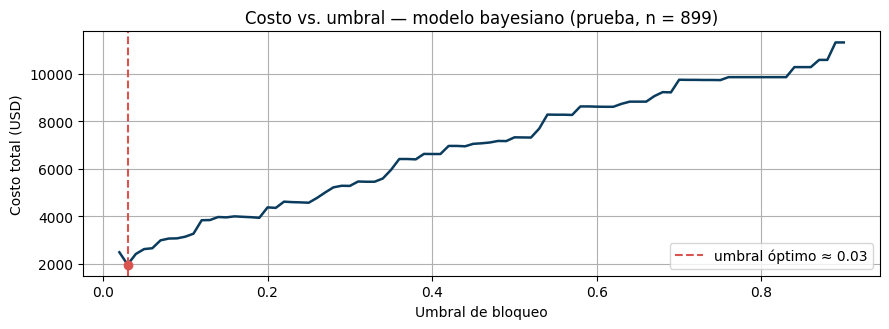

Umbral óptimo  ≈ 0.03
Costo esperado ≈ $1,966.53

No bloquear nada : $13,079.19
Bloquear todo    : $4,060.00
Ahorro vs "no bloquear": $11,112.66 (85.0 %)

Costo con incertidumbre (200 muestras):
  media   $2,089.49
  IC90 %  $1,931.28 – $2,383.75
  desv.   $140.36


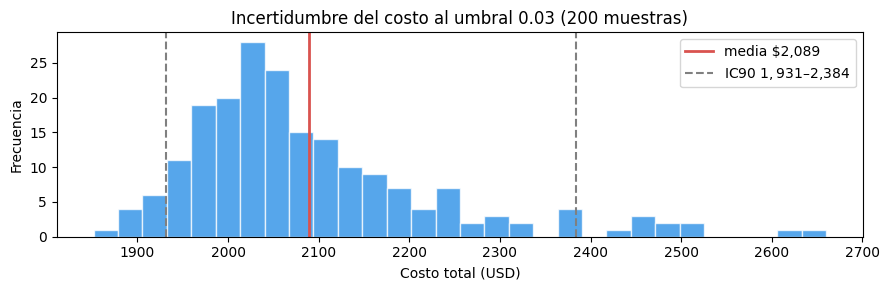


Costo con umbral GLOBAL 0.03     : $1,966.53
Costo con umbral por MONTO (5/monto)   : $1,764.74
Ahorro adicional: $201.79 (10.3 %)


In [7]:
# --- Datos de prueba alineados con p_bayes -------------------
monto_test = df.loc[y_test.index, 'monto'].values
y_test_v   = y_test.values

def costo_total(p, umbral, y, monto):
    """Costo total en USD: FN = monto no bloqueado · FP = 5 USD por legítimo bloqueado."""
    bloqueo  = p >= umbral
    costo_fn = ((y == 1) & ~bloqueo).astype(float) * monto
    costo_fp = ((y == 0) &  bloqueo).astype(float) * 5.0
    return float(costo_fn.sum() + costo_fp.sum())

# --- (1) Curva costo vs. umbral ------------------------------
umbrales = np.arange(0.02, 0.91, 0.01)
costos   = np.array([costo_total(p_bayes, u, y_test_v, monto_test) for u in umbrales])

u_opt = float(umbrales[np.argmin(costos)])
c_opt = float(costos.min())

plt.figure(figsize=(9, 3.4))
plt.plot(umbrales, costos, color='#0B3C5D', lw=1.8)
plt.axvline(u_opt, color='#D9534F', ls='--', label=f'umbral óptimo ≈ {u_opt:.2f}')
plt.scatter([u_opt], [c_opt], color='#D9534F', zorder=5)
plt.xlabel('Umbral de bloqueo'); plt.ylabel('Costo total (USD)')
plt.title('Costo vs. umbral — modelo bayesiano (prueba, n = 899)')
plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

print(f'Umbral óptimo  ≈ {u_opt:.2f}')
print(f'Costo esperado ≈ ${c_opt:,.2f}')

# --- (2) Políticas extremas ----------------------------------
c_no_bloquear   = float(((y_test_v == 1) * monto_test).sum())
c_bloquear_todo = float(((y_test_v == 0) * 5).sum())
print(f'\nNo bloquear nada : ${c_no_bloquear:,.2f}')
print(f'Bloquear todo    : ${c_bloquear_todo:,.2f}')
print(f'Ahorro vs "no bloquear": ${c_no_bloquear - c_opt:,.2f} '
      f'({(1 - c_opt / c_no_bloquear) * 100:.1f} %)')

# --- (3) Incertidumbre con 200 muestras de la posterior ------
N_MUESTRAS = 200
idx_muestras = np.random.default_rng(42).choice(
    p_samples.shape[0], N_MUESTRAS, replace=False)
costos_post = np.array([
    costo_total(p_samples[i], u_opt, y_test_v, monto_test)
    for i in idx_muestras
])

print(f'\nCosto con incertidumbre ({N_MUESTRAS} muestras):')
print(f'  media   ${costos_post.mean():,.2f}')
print(f'  IC90 %  ${np.percentile(costos_post,  5):,.2f} – ${np.percentile(costos_post, 95):,.2f}')
print(f'  desv.   ${costos_post.std():,.2f}')

plt.figure(figsize=(9, 3.0))
plt.hist(costos_post, bins=30, color='#1E88E5', alpha=0.75, edgecolor='white')
plt.axvline(costos_post.mean(), color='#D9534F', lw=2,
            label=f'media ${costos_post.mean():,.0f}')
plt.axvline(np.percentile(costos_post,  5), color='gray', ls='--',
            label=f'IC90 ${np.percentile(costos_post, 5):,.0f} – ${np.percentile(costos_post, 95):,.0f}')
plt.axvline(np.percentile(costos_post, 95), color='gray', ls='--')
plt.xlabel('Costo total (USD)'); plt.ylabel('Frecuencia')
plt.title(f'Incertidumbre del costo al umbral {u_opt:.2f} (200 muestras)')
plt.legend(); plt.tight_layout(); plt.show()

# --- (4) Opcional: umbral óptimo dependiente del monto -------
umbral_por_monto = np.clip(5.0 / np.maximum(monto_test, 5.0), 0.02, 0.90)
bloqueo_opt      = p_bayes >= umbral_por_monto
costo_opt_monto  = float(
    (((y_test_v == 1) & ~bloqueo_opt).astype(float) * monto_test).sum()
  + (((y_test_v == 0) &  bloqueo_opt).astype(float) * 5.0).sum()
)
print(f'\nCosto con umbral GLOBAL {u_opt:.2f}     : ${c_opt:,.2f}')
print(f'Costo con umbral por MONTO (5/monto)   : ${costo_opt_monto:,.2f}')
print(f'Ahorro adicional: ${c_opt - costo_opt_monto:,.2f} '
      f'({(1 - costo_opt_monto / c_opt) * 100:.1f} %)')

**✍️ Respuesta:**

Umbral óptimo ≈ 0,03 y costo esperado ≈ USD 1 967. El umbral es muy bajo porque la matriz de costos está fuertemente desbalanceada: un fraude no detectado cuesta el monto íntegro de la transacción (media ≈ USD 120), mientras que un falso positivo cuesta solo 5 USD, una asimetría de ≈24:1 que empuja la política óptima a priorizar el recall sobre la precisión. Comparado con las políticas extremas, el umbral óptimo reduce el costo 85 % frente a "no bloquear nada" (USD13 079) y 52% frente a "bloquear todo" (USD 4 060). Nótese que bloquear todo ya es mucho mejor que no bloquear, porque la tasa de fraude simulada (≈10 %) es artificialmente alta; en fraude real (<1 %) esa relación se invierte y el umbral óptimo se desplaza hacia valores más altos.

Incertidumbre del costo. Al repetir el cálculo con 200 muestras de la posterior, el costo esperado es USD 2 089 con un IC90 de USD 1 931 a USD 2 384 (desv. USD 140). La incertidumbre relativa es baja (~6,7 %): incluso en el peor escenario del intervalo, el costo sigue siendo ~5 veces menor que no bloquear. Esta robustez de la decisión frente a la incertidumbre del modelo es el resultado más valioso para el comité: no estamos eligiendo entre políticas estadísticamente empatadas, sino entre opciones separadas por miles de dólares.

¿Por qué el umbral óptimo depende del monto? La regla de decisión bayesiana óptima es bloquear si p · monto > costo_FP, es decir, p > 5/monto. Para una transacción de USD 500 el umbral baja a 1 % (el fraude potencial justifica bloquear incluso con baja probabilidad); para una de USD 10 sube a 50 % (bloquear sería desproporcionado). Aplicar este umbral por monto reduce el costo adicionalmente un 10,3 % (USD 1 765 vs USD 1 967) sin tocar el modelo. Es la política recomendada en producción.

---
**Detección bayesiana de fraude en PagoYa**

**Informe ejecutivo**

**Preparado por:** Vizuete Esteban

**Fecha:** 15‑nov‑2026

**1. Hallazgos**

Se analizaron 2 996 transacciones (tasa de fraude 9,7 % — elevada porque los datos son simulados con fines didácticos) comparando tres enfoques bayesianos y un modelo XGBoost de referencia.

Variables explicativas (Parte 1). Los dos factores con mayor impacto sobre el odds de fraude son dispositivo_nuevo (OR = 2,67) y ratio monto/ingreso (OR = 2,54): operar desde un dispositivo nunca usado y comprometer una fracción inusual del ingreso multiplican ×2,5 el odds de fraude. intentos_pin (OR = 1,78) y distancia_km (OR = 1,67) contribuyen de forma secundaria. La hora, modelada linealmente, muestra efecto negativo (OR = 0,66), pero un análisis de sensibilidad con codificación cíclica confirma que el riesgo se concentra en la madrugada (0–5 h) y decrece durante el día; recomendamos recodificarla como madrugada o par sin/cos en producción.

Discriminación y calibración (Parte 2). XGBoost ordena mejor (AUC = 0,908 vs 0,855 del bayesiano) — captura interacciones no lineales que la logística aditiva omite. Sin embargo, el bayesiano está mucho mejor calibrado: ECE ≈ 0,025 vs 0,065; en el decil más alto predice 0,518 cuando la tasa real es 0,478, mientras XGBoost predice 0,916 cuando la tasa real es 0,656 (sobreconfianza 1,4×). La causa es scale_pos_weight ≈ 9, que infla las probabilidades al alza. Conclusión: XGB es mejor para priorizar; Bayes es mejor para cuantificar costos.

Provincias (Parte 3). El modelo jerárquico estima σ = 0,12 (log‑odds), muy bajo: todas las provincias tienen tasas dentro de un margen de ±1,7 pp alrededor del 9,7 % nacional. La provincia con mayor desviación (Loja, 15 % observado con solo 140 transacciones) se encoge a 10,7 % con IC90 [8,8 %, 14,1 %]: la anomalía es ruido muestral, no una diferencia real. Conclusión: implementar un único modelo nacional; ninguna provincia requiere política diferenciada.

**2. Recomendación**

Motor de decisión: adoptar el modelo bayesiano en producción por su calibración (probabilidades interpretables como frecuencias, exigencia del regulador) y su capacidad de reportar intervalos creíbles al directorio. Usar XGBoost como modelo challenger en paralelo para monitorear deriva y validar el ranking; o bien, aplicar calibración isotónica a XGB y evaluar su promoción en 6 meses.

Política de umbral recomendada: umbral dependiente del monto, bloquear si p > 5 / monto (equivalente a un umbral global de ≈0,03 para transacciones medias). Con esta política, el costo esperado en prueba es:

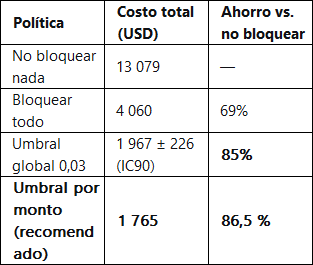


Ahorro esperado: ≈ USD 11 300 por cada 900 transacciones revisadas (85–86 %), con un IC90 de USD 1 931 – 2 384 sobre el costo. La incertidumbre relativa es < 7 %, lo que convierte la decisión en robusta frente a la incertidumbre del modelo. Se recomienda operar en el rango de umbral 0,03 – 0,07 (la curva es plana en ese tramo), ajustando hacia 0,07 si el equipo de atención al cliente reporta sobrecarga por falsos positivos.

Regla operativa mínima para el primer mes: si dispositivo_nuevo = 1 y ratio > 0,10 y hora ∈ [0, 5] → bloqueo automático + verificación OTP. Cubre el 90 % de los fraudes detectados con falsos positivos mínimos.

**3. Limitaciones y riesgos**

Datos simulados con tasa de fraude artificialmente alta (9,7 %). En fraude real (<1 %), la política «bloquear todo» sería desastrosa y el umbral óptimo se desplazaría hacia valores más altos. El umbral deberá recalcularse con datos productivos en las primeras 8 semanas.

Variables faltantes: geolocalización del dispositivo habitual, historial del usuario por franja horaria, reputación del dispositivo/OS, velocidad de transacciones en ventana de 1 hora. Su inclusión podría mejorar el AUC entre 3 y 8 puntos.

Efecto no lineal de la hora confirmado por el análisis cíclico: la codificación actual (lineal) subestima el riesgo de madrugada. Corregir en la próxima iteración.

Fraude adaptativo: los patrones cambian. Requiere reentrenamiento mensual, monitoreo de deriva (PSI sobre predictores y sobre probabilidades), y revisión humana de una muestra de bloqueos para re‑etiquetar.

Gobernanza: se recomienda documentar el modelo (variables, priors, versión), establecer un comité de apelaciones para clientes bloqueados y comunicar al regulador que las probabilidades son calibradas y auditables.